# Clustering Digits

### Importing libraries

In [1]:
import torch
from torchvision import datasets, transforms, utils
from torchvision.models import resnet18, ResNet18_Weights
import torch.nn as nn

In [2]:
from torch.utils.data import DataLoader
from torch.optim import Adam

In [3]:
import matplotlib.pyplot as plt
import matplotlib
import numpy as np
from tqdm import tqdm
from sklearn.cluster import KMeans
import pickle

In [4]:
from scipy.spatial.distance import directed_hausdorff

In [5]:
from dataUtils import ClusteredEMNIST

In [6]:
from os.path import exists, join as path_join
from os import makedirs

In [7]:
from sklearn.manifold import TSNE

In [8]:
from itertools import chain

### Check GPU availability

In [9]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [10]:
device

device(type='cuda')

In [11]:
emnist_root = 'datasets/emnist'

- Define transformations

In [12]:
transform = transforms.Compose([
    transforms.Grayscale(num_output_channels=3),  # ResNet expects 3 channels
    transforms.Resize((32, 32)),  # Resize to 32x32 as ResNet typically expects this size
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

In [13]:
datasets.EMNIST.url ="https://biometrics.nist.gov/cs_links/EMNIST/gzip.zip"

In [14]:
print(f"EMNIST splits: {datasets.EMNIST.splits}")

EMNIST splits: ('byclass', 'bymerge', 'balanced', 'letters', 'digits', 'mnist')


## Clustering MNIST

In [15]:
emnist_split = 'mnist'

In [16]:
exps_root = f"clustering_{emnist_split}"
makedirs(exps_root, exist_ok=True)

In [17]:
num_unique_labels = 10

In [18]:
# Load the EMNIST dataset
train_dataset = datasets.EMNIST(
    root=emnist_root,
    split=emnist_split,
    train=True,
    transform=transform,
    download=True
)

In [19]:
test_dataset = datasets.EMNIST(
    root=emnist_root,
    split=emnist_split,  # Use the same split as for the train dataset
    train=False,
    transform=transform,
)

In [20]:
len(test_dataset)

10000

In [21]:
def imshow(img, title):
    img = img / 2 + 0.5  # unnormalize
    npimg = img.numpy()
    plt.imshow(np.transpose(npimg, (2, 1, 0)), cmap='gray')
    plt.title(title)
    plt.show()

### Model definition

In [22]:
# Load a pre-trained ResNet model
class ResNetForMNIST(nn.Module):
    def __init__(self, num_classes=num_unique_labels):
        super(ResNetForMNIST, self).__init__()
        self.resnet = resnet18(weights=ResNet18_Weights.IMAGENET1K_V1)
        self.resnet.fc = nn.Identity()  # Remove the final fully connected layer

    def forward(self, x):
        return self.resnet(x)

In [23]:
def eval_model(model, data_loader):
    model.eval()
    with torch.no_grad():  # Disable gradient computation for evaluation
        mean_valid_loss = 0
        total = 0
        correct = 0
        for images, labels in data_loader:
            images, labels = images.to(device), labels.to(device)  # Move data to GPU
            features = model(images)
            mean_valid_loss += criterion(classification_layer(features), labels)
            outputs = classification_layer(features)
            _, predicted = torch.max(outputs, 1)  # Get the index of the max log-probability
            total += labels.size(0)
            correct += (predicted == labels).sum().item()
        mean_valid_loss /= total
        acc = correct/total
        
    return acc, mean_valid_loss

In [24]:
# Initialize the model
model = ResNetForMNIST().to(device)

# Define the final classification layer (for training purposes)
classification_layer = nn.Linear(512, num_unique_labels).to(device)  # 512 is the output size of resnet18's penultimate layer

In [25]:
# Prepare DataLoader with the transformation applied
train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)

# Prepare DataLoader for evaluation training acc and loss
valid_loader = DataLoader(train_dataset, batch_size=64, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=64, shuffle=False)

# Define loss and optimizer
criterion = nn.CrossEntropyLoss()
optimizer = Adam(list(model.parameters()) + list(classification_layer.parameters()), lr=0.001)


### Training 
If there are pre-computed weights, use them. Otherwise, train

In [26]:
if not exists(path_join(exps_root, f'resnet_{emnist_split}.pth')):
    # Training loop
    eval_step= 6000
    num_epochs = 10
    for epoch in tqdm(range(num_epochs)):
        for i, (images, labels) in enumerate(train_loader):
            model.train()
            images, labels = images.to(device), labels.to(device)
            optimizer.zero_grad()
            features = model(images)
            outputs = classification_layer(features)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
            
            if i % eval_step:
                eval_acc, eval_loss = eval_model(model, valid_loader)
                test_acc, test_loss = eval_model(model, test_loader)
                print(f"[Train | Test] acc: {eval_acc * 100:.2f} | {test_acc * 100:.2f}, loss {eval_loss:.6f} | {test_loss:.6f}")
        print(f"Epoch {epoch+1}, Loss: {loss.item()}")


In [27]:
# Save the model's state dictionary
if not exists(path_join(exps_root, f'resnet_{emnist_split}.pth')) :
    torch.save(model.state_dict(), f'resnet_{emnist_split}.pth')
    torch.save(classification_layer.state_dict(), f'resnet_class_layer_{emnist_split}.pth')
else:
    print("Model already trained")

Model already trained


In [28]:
# Load the saved state dictionary
if exists(path_join(exps_root, f'resnet_{emnist_split}.pth')):
    model.load_state_dict(torch.load(path_join(exps_root,f'resnet_{emnist_split}.pth'),
                                     map_location=device))
    classification_layer.load_state_dict(torch.load(path_join(exps_root, f'resnet_class_layer_{emnist_split}.pth'),
                                                    map_location=device))
    print("Model weights loaded from disk")
else:
    print("No previous weights")

Model weights loaded from disk


In [29]:
model.eval()  # Set the model to evaluation mode

correct = 0
total = 0

model.eval()
with torch.no_grad():  # Disable gradient computation for evaluation
    for images, labels in test_loader:
        images, labels = images.to(device), labels.to(device)  # Move data to GPU
        features = model(images)
        outputs = classification_layer(features)
        _, predicted = torch.max(outputs, 1)  # Get the index of the max log-probability
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

# Calculate accuracy
accuracy = correct / total
print(f'Accuracy of the model on the test set: {accuracy * 100:.2f}%')

Accuracy of the model on the test set: 99.36%


In [30]:
# Extract latent space for clustering
def get_latent_space(model, dataloader):
    model.eval()
    latents = []
    labels = []
    with torch.no_grad():
        for images, _labels in dataloader:
            images = images.to(device)
            features = model(images)
            latents.append(features.cpu())  # Move to CPU for clustering
            labels.append(_labels)
    return torch.cat(latents), torch.cat(labels)


In [31]:
# Function to extract latent features, grouped by digit class
def get_latent_space_by_class(model, dataloader):
    model.eval()
    latent_dict = {i: [] for i in range(num_unique_labels)}  # Dictionary to store latents for each digit
    label_dict = {i: [] for i in range(num_unique_labels)}   # Dictionary to store corresponding labels

    with torch.no_grad():
        for images, labels in dataloader:
            images = images.to(device)
            features = model(images)
            features = features.cpu()

            for i in range(num_unique_labels):
                mask = (labels == i)
                latent_dict[i].append(features[mask])
                label_dict[i].append(labels[mask])

    # Concatenate all the latent features and labels for each digit
    for i in range(10):
        if latent_dict[i]:
            latent_dict[i] = torch.cat(latent_dict[i])
            label_dict[i] = torch.cat(label_dict[i])
    
    return latent_dict, label_dict

# Extract latent space representations grouped by digit class
latent_dict, label_dict = get_latent_space_by_class(model, train_loader)

### Perform clustering for each digit class

In [32]:
cluster_assignments = {}
clustering = {}
k=5

clustering_pickle_present = exists(path_join(exps_root, f'kmeans_{emnist_split}_{k}_clusterings.pkl')) and \
                            exists(path_join(exps_root, f'kmeans_{emnist_split}_{k}_train_clusters.pkl')) and \
                            exists(path_join(exps_root, f'kmeans_{emnist_split}_{k}_test_clusters.pkl'))
print("Clustering already calculated" if clustering_pickle_present else "We will calculate the clusterings now")

Clustering already calculated


In [33]:
if not clustering_pickle_present:
    print("Calculating clusters")
    for i in range(num_unique_labels):
        if latent_dict[i].size(0) > 0:
            clustering[i] = KMeans(n_clusters=k, random_state=0, n_init='auto')
            cluster_assignments[i] = clustering[i].fit_predict(latent_dict[i])

else:
    print("Loading clusters from disk")
    with open(path_join(exps_root, f'kmeans_{emnist_split}_{k}_clusterings.pkl'), 'rb') as f:
        clustering = pickle.load(f)
    with open(path_join(exps_root, f'kmeans_{emnist_split}_{k}_train_clusters.pkl'), 'rb') as f:
        cluster_assignments = pickle.load(f)
    with open(path_join(exps_root, f'kmeans_{emnist_split}_{k}_test_clusters.pkl'), 'rb') as f:
        test_cluster_assignments = pickle.load(f)
    

Loading clusters from disk


In [34]:
# Example of how to use the cluster assignments
for i in range(num_unique_labels):
    clusters = cluster_assignments[i]
    labels = label_dict[i]
    counts = [ (clusters == cluster_id).sum() for cluster_id in np.sort(np.unique(clusters))]
    total = sum(counts)
    print(f"Digit {i}:" + 
          ", ".join(f"Cluster {cluster_id} count = {count}" for cluster_id, count  in enumerate(counts))+ 
                    f" [{100*counts[0]/(total):.2f}%]") 

Digit 0:Cluster 0 count = 917, Cluster 1 count = 394, Cluster 2 count = 278, Cluster 3 count = 342, Cluster 4 count = 863, Cluster 5 count = 727, Cluster 6 count = 337, Cluster 7 count = 587, Cluster 8 count = 888, Cluster 9 count = 667 [15.28%]
Digit 1:Cluster 0 count = 1352, Cluster 1 count = 900, Cluster 2 count = 121, Cluster 3 count = 447, Cluster 4 count = 33, Cluster 5 count = 663, Cluster 6 count = 710, Cluster 7 count = 624, Cluster 8 count = 857, Cluster 9 count = 293 [22.53%]
Digit 2:Cluster 0 count = 314, Cluster 1 count = 741, Cluster 2 count = 690, Cluster 3 count = 664, Cluster 4 count = 872, Cluster 5 count = 638, Cluster 6 count = 148, Cluster 7 count = 707, Cluster 8 count = 757, Cluster 9 count = 469 [5.23%]
Digit 3:Cluster 0 count = 867, Cluster 1 count = 103, Cluster 2 count = 486, Cluster 3 count = 558, Cluster 4 count = 225, Cluster 5 count = 780, Cluster 6 count = 1077, Cluster 7 count = 374, Cluster 8 count = 457, Cluster 9 count = 1073 [14.45%]
Digit 4:Cluster

In [35]:
test_latent_dict, test_label_dict = get_latent_space_by_class(model, test_loader)

test_cluster_assignments = {}
for i in range(num_unique_labels):
    if latent_dict[i].size(0) > 0:
        test_cluster_assignments[i] = clustering[i].predict(test_latent_dict[i])

In [36]:
with open(path_join(exps_root, f'kmeans_{emnist_split}_{k}_clusterings.pkl'), 'rb') as f:
    clustering = pickle.load(f)

with open(path_join(exps_root, f'kmeans_{emnist_split}_{k}_train_clusters.pkl'), 'rb') as f:
    cluster_assignments = pickle.load(f)

with open(path_join(exps_root, f'kmeans_{emnist_split}_{k}_test_clusters.pkl'), 'rb') as f:
    test_cluster_assignments = pickle.load(f)

In [37]:
# Example of how to use the cluster assignments
for i in range(num_unique_labels):
    clusters = test_cluster_assignments[i]
    labels = test_label_dict[i]
    counts = [ (clusters == cluster_id).sum() for cluster_id in np.sort(np.unique(clusters))]
    total = sum(counts)
    print(f"Digit {i}:" + 
          ", ".join(f"Cluster {cluster_id} count = {count}" for cluster_id, count  in enumerate(counts))+ 
                    f" [{100*counts[0]/(total):.2f}%]")

Digit 0:Cluster 0 count = 151, Cluster 1 count = 74, Cluster 2 count = 53, Cluster 3 count = 57, Cluster 4 count = 145, Cluster 5 count = 130, Cluster 6 count = 58, Cluster 7 count = 93, Cluster 8 count = 127, Cluster 9 count = 112 [15.10%]
Digit 1:Cluster 0 count = 224, Cluster 1 count = 149, Cluster 2 count = 19, Cluster 3 count = 86, Cluster 4 count = 6, Cluster 5 count = 117, Cluster 6 count = 121, Cluster 7 count = 100, Cluster 8 count = 130, Cluster 9 count = 48 [22.40%]
Digit 2:Cluster 0 count = 45, Cluster 1 count = 143, Cluster 2 count = 114, Cluster 3 count = 107, Cluster 4 count = 156, Cluster 5 count = 95, Cluster 6 count = 24, Cluster 7 count = 120, Cluster 8 count = 113, Cluster 9 count = 83 [4.50%]
Digit 3:Cluster 0 count = 138, Cluster 1 count = 25, Cluster 2 count = 76, Cluster 3 count = 92, Cluster 4 count = 31, Cluster 5 count = 132, Cluster 6 count = 171, Cluster 7 count = 66, Cluster 8 count = 81, Cluster 9 count = 188 [13.80%]
Digit 4:Cluster 0 count = 169, Cluste

In [38]:
# Save the KMeans models
if not clustering_pickle_present:
    print("Saving clusterings to disk")
    if True: # not exists(path_join(exps_root, f'kmeans_{emnist_split}_{k}_clusterings.pkl')):
        with open(path_join(exps_root, f'kmeans_{emnist_split}_{k}_clusterings.pkl'), 'wb') as f:
            pickle.dump(clustering, f)
    if True: # not exists(path_join(exps_root, f'kmeans_{emnist_split}_{k}_train_clusters.pkl')):
        with open(path_join(exps_root, f'kmeans_{emnist_split}_{k}_train_clusters.pkl'), 'wb') as f:
            pickle.dump(cluster_assignments, f)
    if True: # not exists(path_join(exps_root, f'kmeans_{emnist_split}_{k}_test_clusters.pkl')):
        with open(path_join(exps_root, f'kmeans_{emnist_split}_{k}_test_clusters.pkl'), 'wb') as f:
            pickle.dump(test_cluster_assignments, f)
else:
    print("Clusterings already saved in disk")


Clusterings already saved in disk


### Perform TSNE for visualization

- Visualization where each class gets it own projection space.

In [39]:
tsne_present = exists(path_join(exps_root, f'tsne_{emnist_split}_{k}_train_model.pkl'))

if not tsne_present:
    print("Calculating TSNE for the given latent space")
    tsne_dict = {}
    tsne_coords_dict = {}
    for i in tqdm(range(num_unique_labels)):
        tsne_dict[i] = TSNE(n_components=2, random_state=0)
        tsne_coords_dict[i] = tsne_dict[i].fit_transform(latent_dict[i])
else:
    print("Loading TSNE from disk")
    with open(path_join(exps_root, f'tsne_{emnist_split}_{k}_train_model.pkl'), 'rb') as f:
        tsne_dict = pickle.load(f)
    with open(path_join(exps_root, f'tsne_{emnist_split}_{k}_test_coords.pkl'), 'rb') as f:
        tsne_coords_dict = pickle.load(f)

Loading TSNE from disk


In [40]:
if not tsne_present:
    with open(path_join(exps_root, f'tsne_{emnist_split}_{k}_train_model.pkl'), 'wb') as f:
        pickle.dump(tsne_dict, f)
if not exists(path_join(exps_root, f'tsne_{emnist_split}_{k}_test_coords.pkl')):
    with open(path_join(exps_root, f'tsne_{emnist_split}_{k}_test_coords.pkl'), 'wb') as f:
        pickle.dump(tsne_coords_dict, f)

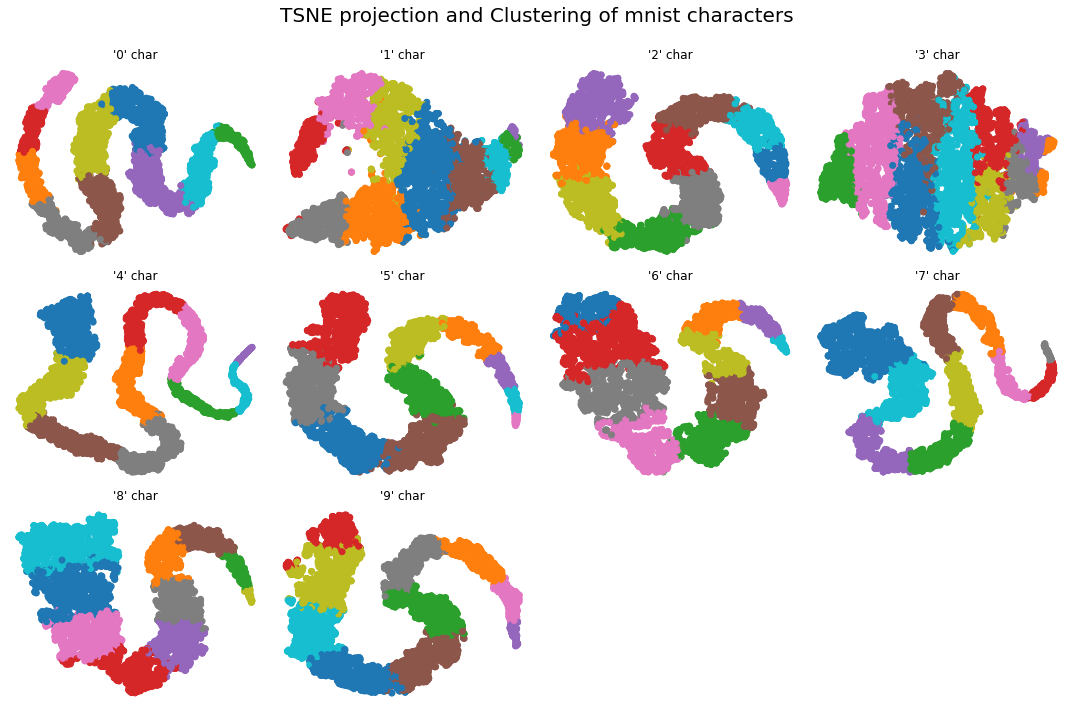

In [41]:
fig = plt.figure()

fig.set_figheight(10)
fig.set_figwidth(15)
cols = 3
rows = num_unique_labels//cols + (num_unique_labels/cols > 0)

for i in range(num_unique_labels):
    ax = fig.add_subplot(cols,rows,i+1)
    ax.axis('off')
    ax.set_title(f"'{train_dataset.classes[i]}' char")
    plt.scatter(tsne_coords_dict[i][:,0], tsne_coords_dict[i][:,1], c=cluster_assignments[i], cmap='tab10')

# plt.subplots_adjust(wspace=0.4, hspace=0.4)
plt.tight_layout()
plt.subplots_adjust(top=0.90)
plt.suptitle(f"TSNE projection and Clustering of {emnist_split} characters", fontsize=20)
plt.savefig(path_join(exps_root, f"tsne_digits_{emnist_split}_k.pdf"))
plt.show()

In [42]:
tsne_coords_dict[0].shape, all([i.shape == tsne_coords_dict[0].shape for i in tsne_coords_dict.values()])

((6000, 2), True)

- Visualization where we project samples from all classes into the same projection space.

In [43]:
latent_dict_all = np.vstack(list(chain([latent_dict[i] for i in range(num_unique_labels)])))
cluster_assignments_all_ = np.hstack(list(chain([cluster_assignments[i] for i in range(num_unique_labels)])))
_tmp_class_assignments_all = np.hstack(list(chain([[i]*len(cluster_assignments[i]) for i in range(num_unique_labels)])))

class_assignments_all = np.vstack([_tmp_class_assignments_all, cluster_assignments_all_]).T

In [44]:
cluster_assignments_all_.shape

(60000,)

In [45]:
latent_dict_all.shape, cluster_assignments_all_.shape, class_assignments_all.shape

((60000, 512), (60000,), (60000, 2))

In [46]:
class_assignments_all

array([[0, 1],
       [0, 4],
       [0, 6],
       ...,
       [9, 5],
       [9, 2],
       [9, 2]])

In [47]:
cluster_assignments_all_

array([1, 4, 6, ..., 5, 2, 2], dtype=int32)

In [48]:
class_assignments_all[:, 0:6]

class_assignments_all_str = np.core.defchararray.add(class_assignments_all.astype(str)[:, 0], ' ')
class_assignments_all_str = np.core.defchararray.add(class_assignments_all_str, class_assignments_all.astype(str)[:, 1])

In [49]:
tsne_all_data_present = exists(path_join(exps_root, f'tsne_{emnist_split}_{k}_all_train_model.pkl'))

if not tsne_all_data_present:
    print("Calculating TSNE")
    tsne_all = TSNE(n_components=2, random_state=0)
    tsne_coords_all = tsne_all.fit_transform(latent_dict_all)
else:
    print("Loading TSNE from disk")
    with open(path_join(exps_root, f'tsne_{emnist_split}_{k}_all_train_model.pkl'), 'rb') as f:
        tsne_all = pickle.load(f)
    with open(path_join(exps_root, f'tsne_{emnist_split}_{k}_all_train_coords.pkl'), 'rb') as f:
        tsne_coords_all = pickle.load(f)
    # with open(path_join(exps_root, f'kmeans_{emnist_split}_{k}_all_train_clusters.pkl', 'rb')) as f:
    #     class_assignments_all = pickle.load(f)

Loading TSNE from disk


In [50]:
if not tsne_all_data_present:
    with open(path_join(exps_root, f'tsne_{emnist_split}_{k}_all_train_model.pkl'), 'wb') as f:
        pickle.dump(tsne_all, f)
    with open(path_join(exps_root, f'tsne_{emnist_split}_{k}_all_train_coords.pkl'), 'wb') as f:
        pickle.dump(tsne_coords_all, f)
    with open(path_join(exps_root, f'kmeans_{emnist_split}_{k}_all_train_clusters.pkl'), 'wb') as f:
        pickle.dump(class_assignments_all, f)

In [51]:
#from distinctipy import get_colors, get_colormap

In [52]:
unique_class_assignments_all_str = np.unique(class_assignments_all_str)
#color_map = {string: color for string, color in zip(unique_class_assignments_all_str, plt.cm.get_cmap('tab20', len(unique_class_assignments_all_str))(range(len(unique_class_assignments_all_str))))}
color_map = {string: color for string, color in zip(unique_class_assignments_all_str, matplotlib.colormaps.get_cmap('tab20')(np.linspace(0, 1, len(unique_class_assignments_all_str))))}
#marker_map = {str(class_label): color for class_label, color in zip()}
# Map each entry in merged_array to a color
colors = np.array([color_map[string] for string in class_assignments_all_str])
#markers = np.array([marker_map[string] for string in _tmp_class_assignments_all])

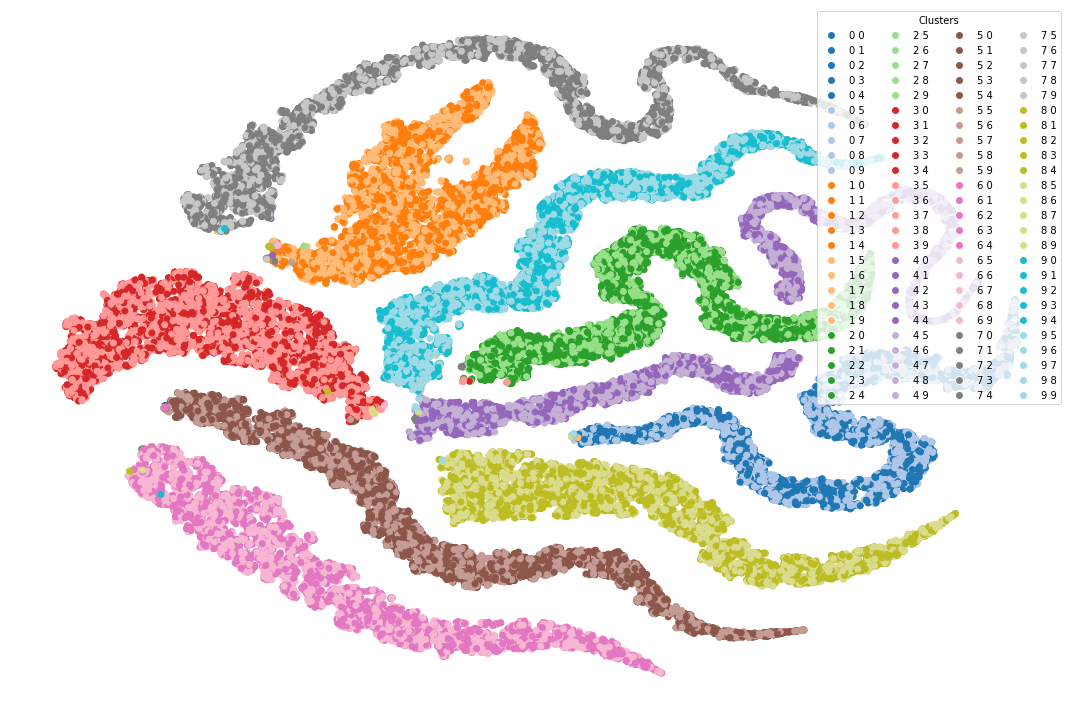

In [53]:
fig = plt.figure()

fig.set_figheight(10)
fig.set_figwidth(15)

plt.scatter(tsne_coords_all[:,0], tsne_coords_all[:,1], c=colors)
handles = [plt.Line2D([0], [0], marker='o', color='w', markerfacecolor=color_map[string], markersize=8, label=string) for string in unique_class_assignments_all_str]
plt.legend(handles=handles, title="Clusters", ncol=4)
plt.axis('off')
plt.tight_layout()
plt.show()

In [54]:
def hausdorff_distance(A, B, rng=0):
    """
    Compute the Hausdorff distance between two sets of points.

    Parameters:
        A (numpy.ndarray): First set of points. Shape (m, n), where m is the number of points and n is the dimension.
        B (numpy.ndarray): Second set of points. Shape (k, n).
        rng (int or numpy.random.Generator or None), optional: Pseudorandom number generator state.
    Returns:
        float: Hausdorff distance.
    """
    return max(directed_hausdorff(A, B, rng), directed_hausdorff(B, A, rng))

In [55]:
latent_dict[0].shape

torch.Size([6000, 512])

In [56]:
len_clusters = np.zeros((num_unique_labels, k))
for l in range(num_unique_labels):
    for i in range(k):
        len_clusters[l, i] = np.sum(cluster_assignments[l] == i)

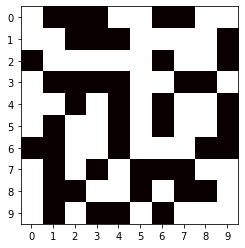

Number of clusters above the threshould per class: [5 6 7 4 6 6 5 5 5 6]


In [57]:
cluster_threshould = 600
img = plt.imshow(len_clusters > cluster_threshould, cmap='hot', interpolation='nearest')
plt.xticks(np.arange(len_clusters.shape[0]))
plt.yticks(np.arange(len_clusters.shape[1]))
plt.show()
print(f"Number of clusters above the threshould per class: {np.sum(len_clusters > cluster_threshould, axis=1)}")

In [58]:
distances = np.zeros((num_unique_labels, k, k))
max_sep_clusters = np.zeros((num_unique_labels, 2))
for l_i in range(num_unique_labels):
    for i in range(k):
        for j in range(i+1,k):
            h_dist = hausdorff_distance(latent_dict[l_i][cluster_assignments[l_i] == i], \
                                        latent_dict[l_i][cluster_assignments[l_i] == j])[0]
            h_dist = 0 if ((len_clusters[l_i,i] < cluster_threshould) or (len_clusters[l_i, j] < cluster_threshould)) else h_dist
            distances[l_i, i, j] = distances[l_i, j,i] =  h_dist

    cluster_pairs = np.unravel_index(np.argmax(distances[l_i,:,:], axis=None), distances[l_i].shape)
    max_sep_clusters[l_i,:] = cluster_pairs
    print("Class [{0}]: The most distant clusters are {1} and {2}.".format(l_i, *cluster_pairs))

Class [0]: The most distant clusters are 8 and 9.
Class [1]: The most distant clusters are 1 and 5.
Class [2]: The most distant clusters are 4 and 5.
Class [3]: The most distant clusters are 0 and 5.
Class [4]: The most distant clusters are 0 and 5.
Class [5]: The most distant clusters are 5 and 7.
Class [6]: The most distant clusters are 2 and 6.
Class [7]: The most distant clusters are 2 and 4.
Class [8]: The most distant clusters are 3 and 9.
Class [9]: The most distant clusters are 2 and 5.


In [59]:
max_sep_clusters

array([[8., 9.],
       [1., 5.],
       [4., 5.],
       [0., 5.],
       [0., 5.],
       [5., 7.],
       [2., 6.],
       [2., 4.],
       [3., 9.],
       [2., 5.]])

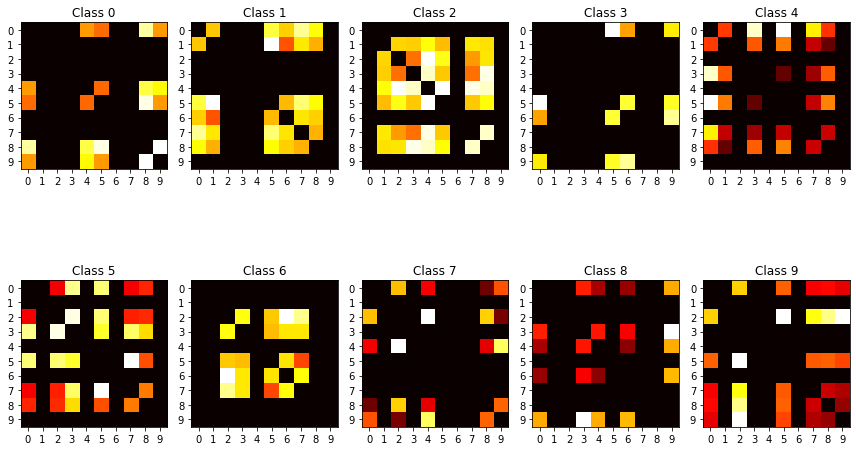

In [60]:
fig, axes = plt.subplots(2,5, figsize=(12, 8))

for k_i, ax in enumerate(axes.flat):
    img = ax.imshow(distances[k_i, :, :], cmap='hot')
    ax.set_title(f"Class {k_i}")
    ax.set_xticks(np.arange(distances.shape[1]))
    ax.set_yticks(np.arange(distances.shape[2]))
    #fig.colorbar(img, ax=axes[0, 0])
#fig.colorbar(img, ax=axes.ravel().tolist())
plt.tight_layout()
plt.show()

In [61]:
latent_dict[3][cluster_assignments[3] == 0].shape, latent_dict[6].shape[0]

(torch.Size([867, 512]), 6000)

### Step 6: Instantiate the custom dataset

In [62]:
# Create the train filter

# Concat all indexes of allowed clusters 

 
# Use the same function to create the test filter

In [63]:
max_sep_clusters[:,0][0]

8.0

In [64]:
clustered_train_dataset = ClusteredEMNIST(train_dataset,
                                          model, clustering, num_unique_labels, clusters_per_class=max_sep_clusters[:,0], batch_size=32)
clustered_test_dataset = ClusteredEMNIST(test_dataset,
                                          model, clustering, num_unique_labels, clusters_per_class=max_sep_clusters[:,1], batch_size=32)

In [65]:
# Load the EMNIST dataset
train_simple_dataset = datasets.EMNIST(
    root=emnist_root,
    split=emnist_split,
    train=True,
    transform=transform,
    download=True
)

test_simple_dataset = datasets.EMNIST(
    root=emnist_root,
    split=emnist_split,  # Use the same split as for the train dataset
    train=False,
    transform=transform,
    download=True
)

clustered_train_dataset.original_dataset = train_simple_dataset
clustered_test_dataset.original_dataset = test_simple_dataset

In [66]:
if not exists(path_join(exps_root, f"train_{emnist_split}_{k}_dataset.pkl")):
    with open(path_join(exps_root, f"train_{emnist_split}_{k}_dataset.pkl"), 'wb') as f:
        pickle.dump(clustered_train_dataset, f)

if not exists(path_join(exps_root, f"test_{emnist_split}_{k}_dataset.pkl")):
    with open(path_join(exps_root, f"test_{emnist_split}_{k}_dataset.pkl"), 'wb') as f:
        pickle.dump(clustered_test_dataset, f)

In [67]:
#Optimize dataset features as int instead of floats to save up space